In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

sns.set_theme(style="whitegrid")

df = pd.read_csv(
    "Sample - Superstore.csv",
    encoding="latin1"
)

df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (51290, 24)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,42433,AG-2011-2040,1/1/2011,6/1/2011,Standard Class,TB-11280,Toby Braunhardt,Consumer,Constantine,Constantine,...,OFF-TEN-10000025,Office Supplies,Storage,"Tenex Lockers, Blue",408.300,2,0.0,106.140,35.46,Medium
1,22253,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,JH-15985,Joseph Holt,Consumer,Wagga Wagga,New South Wales,...,OFF-SU-10000618,Office Supplies,Supplies,"Acme Trimmer, High Speed",120.366,3,0.1,36.036,9.72,Medium
2,48883,HU-2011-1220,1/1/2011,5/1/2011,Second Class,AT-735,Annie Thurman,Consumer,Budapest,Budapest,...,OFF-TEN-10001585,Office Supplies,Storage,"Tenex Box, Single Width",66.120,4,0.0,29.640,8.17,High
3,11731,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,EM-14140,Eugene Moren,Home Office,Stockholm,Stockholm,...,OFF-PA-10001492,Office Supplies,Paper,"Enermax Note Cards, Premium",44.865,3,0.5,-26.055,4.82,High
4,22255,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,JH-15985,Joseph Holt,Consumer,Wagga Wagga,New South Wales,...,FUR-FU-10003447,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",113.670,5,0.1,37.770,4.70,Medium


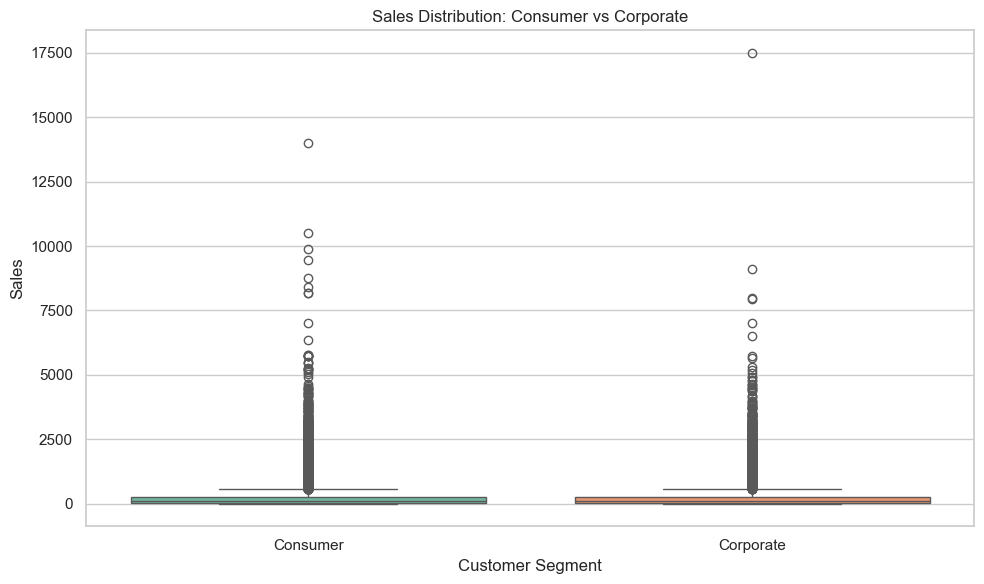

In [4]:
comparison_df = df[
    df["Segment"].isin(["Consumer", "Corporate"])
]

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=comparison_df,
    x="Segment",
    y="Sales",
    hue="Segment",
    palette="Set2",
    legend=False
)

plt.title("Sales Distribution: Consumer vs Corporate")
plt.xlabel("Customer Segment")
plt.ylabel("Sales")

plt.tight_layout()
plt.show()

In [5]:
sales = df["Sales"].dropna()

print("Total Sales Records:", len(sales))
print("Sales data extracted successfully!")

Total Sales Records: 51290
Sales data extracted successfully!


In [6]:
mean_value = sales.mean()

median_value = sales.median()

mode_value = sales.mode()

print("CENTRAL TENDENCY")
print("--------------------------")

print("Mean:", round(mean_value, 2))
print("Median:", round(median_value, 2))
print("Mode:", mode_value.tolist())

CENTRAL TENDENCY
--------------------------
Mean: 246.49
Median: 85.05
Mode: [12.96]


In [7]:
variance_value = sales.var()

std_value = sales.std()

print("MEASURES OF DISPERSION")
print("--------------------------")

print("Variance:", round(variance_value, 2))
print("Standard Deviation:", round(std_value, 2))

MEASURES OF DISPERSION
--------------------------
Variance: 237719.98
Standard Deviation: 487.57


In [8]:
descriptive_stats = pd.DataFrame({
    "Statistical Measure": [
        "Mean",
        "Median",
        "Mode",
        "Variance",
        "Standard Deviation"
    ],

    "Value": [
        mean_value,
        median_value,
        mode_value.iloc[0],
        variance_value,
        std_value
    ]
})

display(descriptive_stats.round(2))

,Statistical Measure,Value
0,Mean,246.49
1,Median,85.05
2,Mode,12.96
3,Variance,237719.98
4,Standard Deviation,487.57


### Interpretation of Descriptive Statistics

The mean and median help understand the central tendency
of sales transactions.

The difference between the mean and median indicates
whether unusually high or low transaction values influence
the average.

Variance and standard deviation help measure the
variability of sales transactions.

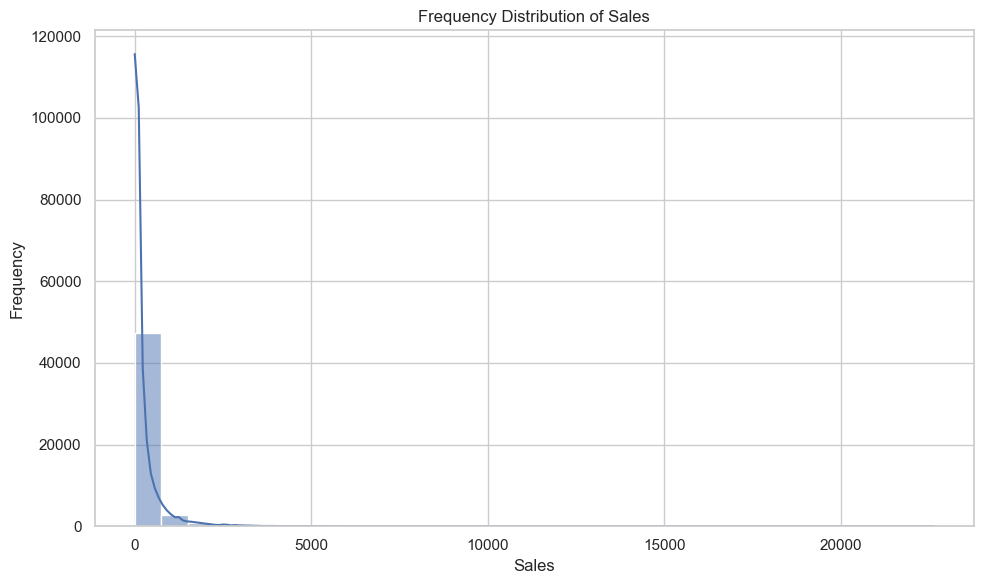

In [9]:
plt.figure(figsize=(10, 6))

sns.histplot(
    sales,
    bins=30,
    kde=True
)

plt.title("Frequency Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [10]:
skewness = sales.skew()

print("Sales Skewness:", round(skewness, 3))

if skewness > 0.5:
    print("Distribution is Positively Skewed (Right Skewed)")

elif skewness < -0.5:
    print("Distribution is Negatively Skewed (Left Skewed)")

else:
    print("Distribution is Approximately Symmetrical")

Sales Skewness: 8.138
Distribution is Positively Skewed (Right Skewed)


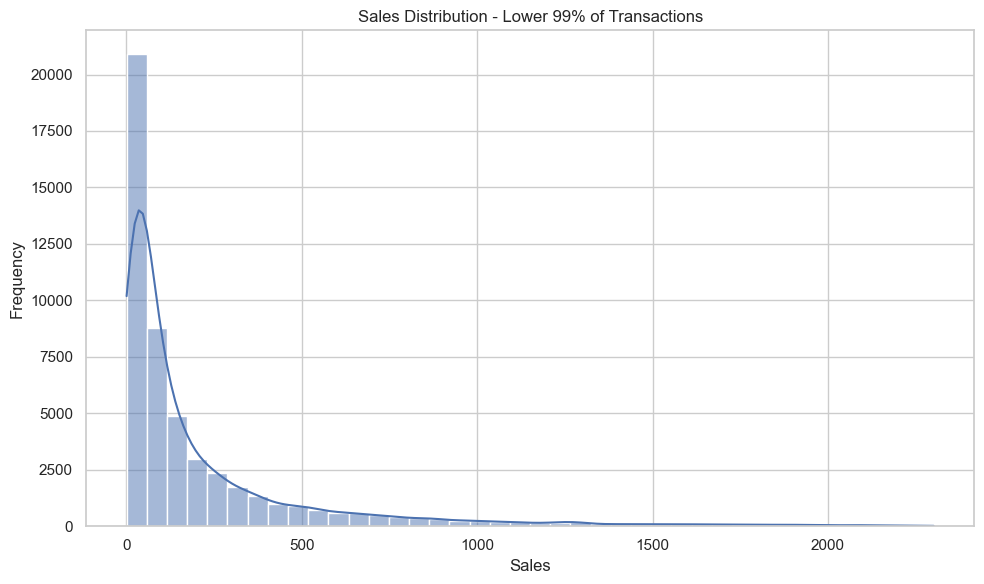

In [11]:
upper_limit = sales.quantile(0.99)

plt.figure(figsize=(10, 6))

sns.histplot(
    sales[sales <= upper_limit],
    bins=40,
    kde=True
)

plt.title("Sales Distribution - Lower 99% of Transactions")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Interpretation of Frequency Distribution

The sales distribution is positively skewed (right-skewed).

Most transactions are concentrated at relatively lower
sales values, while a smaller number of transactions have
significantly higher values.

This indicates that high-value transactions influence
the overall average sales.

In [12]:
percentiles = sales.quantile([
    0.10,
    0.25,
    0.50,
    0.75,
    0.90
])

print("SALES PERCENTILES")

display(percentiles)

SALES PERCENTILES


0.10     13.680000
0.25     30.758625
0.50     85.053000
0.75    251.053200
0.90    632.225736
Name: Sales, dtype: float64

In [13]:
Q1 = sales.quantile(0.25)

Q2 = sales.quantile(0.50)

Q3 = sales.quantile(0.75)

IQR = Q3 - Q1

print("First Quartile (Q1):", round(Q1, 2))

print("Second Quartile (Q2):", round(Q2, 2))

print("Third Quartile (Q3):", round(Q3, 2))

print("Interquartile Range (IQR):", round(IQR, 2))

First Quartile (Q1): 30.76
Second Quartile (Q2): 85.05
Third Quartile (Q3): 251.05
Interquartile Range (IQR): 220.29


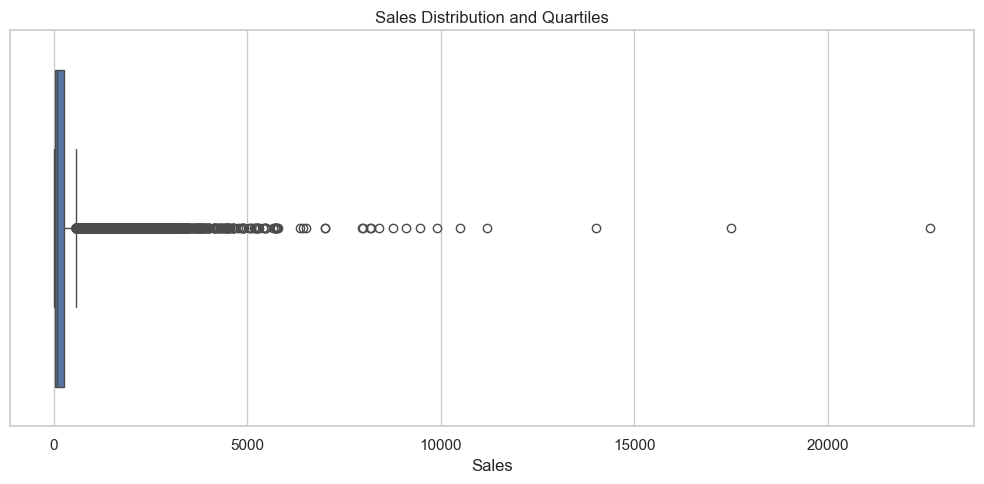

In [14]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=sales)

plt.title("Sales Distribution and Quartiles")
plt.xlabel("Sales")

plt.tight_layout()
plt.show()

### Interpretation of Percentiles and Quartiles

Q1 represents the value below which 25% of sales
observations fall.

Q2 represents the median, dividing the observations
into two equal halves.

Q3 represents the value below which 75% of sales
observations fall.

The Interquartile Range (IQR) represents the spread
of the middle 50% of sales observations.

Quartile analysis helps understand transaction
distribution and identify potential outliers.

In [19]:
group_summary = comparison_df.groupby("Segment")["Sales"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(group_summary.round(2))

,count,mean,median,std,min,max
Segment,,,,,,
Consumer,26518,245.42,85.00,477.13,0.44,13999.96
Corporate,15429,247.89,85.44,486.04,0.56,17499.95


In [20]:
consumer_median = group_summary.loc["Consumer", "median"]

corporate_median = group_summary.loc["Corporate", "median"]

print("Consumer Median:", round(consumer_median, 2))

print("Corporate Median:", round(corporate_median, 2))

if consumer_median > corporate_median:
    print("Consumer segment has a higher median sales value.")

elif corporate_median > consumer_median:
    print("Corporate segment has a higher median sales value.")

else:
    print("Both segments have equal median sales values.")

Consumer Median: 85.0
Corporate Median: 85.44
Corporate segment has a higher median sales value.


In [21]:
consumer_std = group_summary.loc["Consumer", "std"]

corporate_std = group_summary.loc["Corporate", "std"]

print("Consumer Standard Deviation:", round(consumer_std, 2))

print("Corporate Standard Deviation:", round(corporate_std, 2))

if consumer_std > corporate_std:
    print("Consumer sales have greater variability.")

elif corporate_std > consumer_std:
    print("Corporate sales have greater variability.")

else:
    print("Both segments have equal variability.")

Consumer Standard Deviation: 477.13
Corporate Standard Deviation: 486.04
Corporate sales have greater variability.


### Customer Segment Comparison

The Consumer and Corporate segments are compared using
their mean, median, and standard deviation.

The median indicates the typical transaction value,
while standard deviation helps understand the variability
within each customer segment.

The box plot provides a visual comparison of the
distribution and potential outliers.

In [23]:
summary = pd.DataFrame({
    "Metric": [
        "Count",
        "Mean",
        "Median",
        "Mode",
        "Variance",
        "Standard Deviation",
        "Skewness",
        "10th Percentile",
        "25th Percentile",
        "50th Percentile",
        "75th Percentile",
        "90th Percentile",
        "IQR"
    ],

    "Value": [
        sales.count(),
        mean_value,
        median_value,
        mode_value.iloc[0],
        variance_value,
        std_value,
        skewness,
        sales.quantile(0.10),
        Q1,
        Q2,
        Q3,
        sales.quantile(0.90),
        IQR
    ]
})

display(summary.round(2))

,Metric,Value
0,Count,51290.00
1,Mean,246.49
2,Median,85.05
3,Mode,12.96
4,Variance,237719.98
5,Standard Deviation,487.57
6,Skewness,8.14
7,10th Percentile,13.68
8,25th Percentile,30.76
9,50th Percentile,85.05


In [24]:
import os

os.makedirs("outputs", exist_ok=True)

summary.to_csv(
    "outputs/descriptive_statistics_summary.csv",
    index=False
)

group_summary.to_csv(
    "outputs/customer_segment_comparison.csv"
)

print("Statistical summary exported successfully!")

Statistical summary exported successfully!


In [25]:
plt.savefig(
    "outputs/segment_sales_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 1000x600 with 0 Axes>

# Business Insights and Conclusion

## 1. Central Tendency
Mean, median, and mode were calculated to understand
the central tendency of business sales transactions.

## 2. Distribution Analysis
The histogram and skewness calculation helped identify
the shape of the sales distribution.

## 3. Variability Analysis
Variance and standard deviation were used to measure
the spread of sales values.

## 4. Quartile Analysis
Percentiles, quartiles, and IQR were calculated to
understand sales distribution and identify potential
outliers.

## 5. Customer Segment Comparison
Consumer and Corporate sales distributions were compared
using box plots and statistical summaries.

## 6. Business Recommendations
- Monitor high-value sales transactions.
- Use median values alongside mean values in business reporting.
- Analyze sales variability across customer segments.
- Use quartile analysis to understand transaction patterns.
- Develop customer strategies based on segment-level findings.

## Conclusion
Descriptive statistical analysis helps summarize business
data, identify distribution patterns, understand variability,
and compare customer segments.

These techniques support effective business reporting
and data-driven decision-making.